# 24. 로그 연면적 포함5변수 쌍대순위: 기초40명 이상

사용자 지정40명 기준으로 원래126개 중53개를 제외한73개(운정34/킨텍스21/대곡18)를 학습·검증에 사용한다. 기존23번은 보존한다.

입력: 개통 전 권역 내 수요 비중(%), log(1+개통 전 승차인원), 보행시간(분, 원 단위), 경쟁 목적지 비율(%), log(1+건축물 연면적[천㎡]).

- 원래126개 기준 권역변화율·사전 비중·정답을 유지한다. 결과를 보고40명 기준을 조정하지 않는다.
- 외부LOSO3회, 학습역 내부LOSO의 평균AUC로 C선택·표준화. 검증역을 학습과 설정 선택에서 제외한다.
- 전체학습5변수 모형도 같은73개에 한정해 역별 순위를 다시 매긴 후 비교한다. 기존 상위27개 중40명 이상만 남긴 결과와 다르다.
- 다른 표본(126/102/73개)의 성능을 직접 차감해 학습 개선으로 해석하지 않는다. 40명 미만을 C에서0점/감소로 표시하면 안 되며 적용대상 아님·별도 검토로 남긴다.
- 하루40명은 이번 적용범위 기준이며 버스1대 공급유지 필요성을 판정하는 기준은 아니다.
- 같은 자료의 반복 탐색이므로 최종 일반화/GTX-C 성능 입증이 아니다. CSV·모델·그림 파일 자동 저장 없음.


In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import importlib.util
import pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
paths=[*sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir()), Path.cwd(),Path.cwd()/'analysis',Path.cwd()/'gtx_a_bus_analysis'/'analysis',Path.cwd()/'github_2026-UROP'/'gtx_a_bus_analysis'/'analysis']
ANALYSIS=next((p for p in paths if (p/'24_쌍대순위_5변수_40명이상.py').exists()),None)
if ANALYSIS is None:raise FileNotFoundError('프로젝트 또는 analysis 폴더에서 실행하세요.')
spec=importlib.util.spec_from_file_location('pairwise_ge40',next((UROP_ROOT / 'code').rglob('24_쌍대순위_5변수_40명이상.py')))
experiment=importlib.util.module_from_spec(spec);spec.loader.exec_module(experiment)
fonts={f.name for f in font_manager.fontManager.ttflist}
font=next((f for f in ['AppleGothic','Apple SD Gothic Neo','NanumGothic','Malgun Gothic','Noto Sans CJK KR'] if f in fonts),None)
if font:plt.rcParams['font.family']=font
plt.rcParams.update({'axes.unicode_minus':False,'figure.dpi':110,'font.size':11})
pd.set_option('display.max_columns',25)
oof,rows,overall,tops,settings,coverage=experiment.evaluate()
display(coverage.round(4));display(settings.round(4))
display(overall.round(4));display(rows.round(4))

,권역,원래n,40명이상n,제외n,유지된개통전승차비율,고정권역변화율
0,운정중앙,63,34,29,0.9462,-70.5592
1,킨텍스,26,21,5,0.9888,-69.7301
2,대곡,37,18,19,0.9069,-61.2510


,검증역,학습n,검증n,학습양방향쌍수,선택C,내부역평균AUC
0,운정중앙,39,34,374,0.0010,0.6669
1,킨텍스,52,21,700,100.0000,0.5373
2,대곡,55,18,766,31.6228,0.6415


,모형,평가n,역평균AUC,격자수가중AUC,전체쌍Loss,상위수,적중수,상위Precision,상위실제Y중앙값
0,전체학습_같은73개평가,73,0.7393,0.7559,0.5505,16,10,0.625,4.1894
1,40명이상재학습,73,0.5732,0.5481,0.7640,16,8,0.500,-0.2065


,모형,검증역,n,AUC,PairwiseLoss,비교쌍수,권역상대유지비율,상위수,적중수,Precision20,Lift20,상위실제Y중앙값
0,전체학습_같은73개평가,대곡,18,0.6883,0.5942,77,0.3889,4,3,0.7500,1.9286,9.5423
1,전체학습_같은73개평가,운정중앙,34,0.8205,0.5557,273,0.3824,7,5,0.7143,1.8681,4.4862
2,전체학습_같은73개평가,킨텍스,21,0.7091,0.5070,110,0.4762,5,2,0.4000,0.8400,-6.5857
3,40명이상재학습,운정중앙,34,0.4469,0.7091,273,0.3824,7,2,0.2857,0.7473,-2.2408
4,40명이상재학습,킨텍스,21,0.6364,0.9490,110,0.4762,5,4,0.8000,1.6800,1.4374
5,40명이상재학습,대곡,18,0.6364,0.6946,77,0.3889,4,2,0.5000,1.2857,3.7825


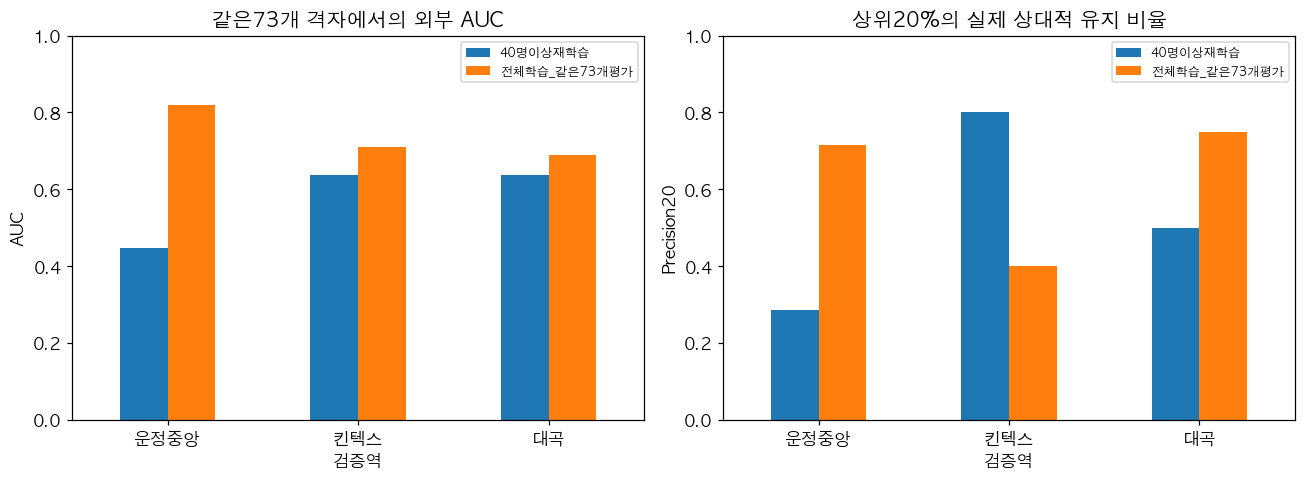

,모형,검증역,상위비율,K,적중수,Precision,Lift,실제Y중앙값
0,전체학습_같은73개평가,대곡,0.1,2,1,0.5000,1.2857,3.7825
1,전체학습_같은73개평가,대곡,0.2,4,3,0.7500,1.9286,9.5423
2,전체학습_같은73개평가,대곡,0.3,6,4,0.6667,1.7143,5.7532
3,전체학습_같은73개평가,운정중앙,0.1,4,4,1.0000,2.6154,12.4382
4,전체학습_같은73개평가,운정중앙,0.2,7,5,0.7143,1.8681,4.4862
5,전체학습_같은73개평가,운정중앙,0.3,11,9,0.8182,2.1399,3.8926
6,전체학습_같은73개평가,킨텍스,0.1,3,2,0.6667,1.4000,0.2829
7,전체학습_같은73개평가,킨텍스,0.2,5,2,0.4000,0.8400,-6.5857
8,전체학습_같은73개평가,킨텍스,0.3,7,4,0.5714,1.2000,0.2829
9,40명이상재학습,운정중앙,0.1,4,1,0.2500,0.6538,-4.9667


In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric,title in [(axes[0],'AUC','같은73개 격자에서의 외부 AUC'),(axes[1],'Precision20','상위20%의 실제 상대적 유지 비율')]:
 rows.pivot(index='검증역',columns='모형',values=metric).reindex(experiment.STATIONS).plot.bar(ax=ax)
 ax.set(xlabel='검증역',ylabel=metric,title=title,ylim=(0,1));ax.tick_params(axis='x',rotation=0);ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(tops.round(4))

## 새모형 상위16개

실제Y는 사후 진단이며 모형의 예측 변화율이 아니다.

In [3]:
selected=oof[oof['상위20']].sort_values(['nearest_station','순위'])
with pd.option_context('display.max_rows',30):
 display(selected[['nearest_station','셀 ID','순위','board_2024_all','board_2025_all','R_s','R_i','Y','점수']].round(3))
print('상위수:',len(selected),'| Y>0:',int((selected.Y>0).sum()),'| 실제Y중앙값:',round(selected.Y.median(),3),'%p')

상위수: 16 | Y>0: 8 | 실제Y중앙값: -0.206 %p


,nearest_station,셀 ID,순위,board_2024_all,board_2025_all,R_s,R_i,Y,점수
55,대곡,12461,1,595.0,283.0,-61.251,-52.437,8.814,-4.582
56,대곡,5631,2,51.0,25.0,-61.251,-50.980,10.271,-9.173
57,대곡,1712,3,43.0,16.0,-61.251,-62.791,-1.540,-9.175
58,대곡,3424,4,64.0,24.0,-61.251,-62.500,-1.249,-9.215
0,운정중앙,5217,1,619.0,137.0,-70.559,-77.868,-7.308,0.263
1,운정중앙,10778,2,1123.0,381.0,-70.559,-66.073,4.486,0.234
2,운정중앙,1118,3,179.0,48.0,-70.559,-73.184,-2.625,0.202
3,운정중앙,1115,4,111.0,17.0,-70.559,-84.685,-14.125,0.169
4,운정중앙,11811,5,247.0,71.0,-70.559,-71.255,-0.696,0.169
5,운정중앙,2586,6,96.0,32.0,-70.559,-66.667,3.893,0.158


## 실행 결과

| 검증역 | 표본 | AUC | 상위20% 실제 상대적 유지 | Precision | Lift |
|---|---:|---:|---:|---:|---:|
| 운정중앙 |34|.447|2/7|28.6%|.75|
| 킨텍스 |21|.636|4/5|80.0%|1.68|
| 대곡 |18|.636|2/4|50.0%|1.29|

역별 AUC 평균=.5732, 상위16개 중8개 적중(50.0%), 실제Y 중앙값−.21%p다. 전체 비교쌍 손실=.7640으로 두 격자에 같은 점수를 주는 기준 .6931보다 크다. 특히 운정중앙에서 유지 격자를 높은 순위에 놓는 성능이 약화됐다.

공통73개에서 기존 전체학습 모형은 역평균AUC=.7393, 상위10/16(62.5%), 손실=.5505였다. 따라서 평가집단이 바뀐 효과와 별개로, 이번에는40명 이상만 남겨 재학습하는 절차가 기존 전체학습 모형보다 낮은 성능을 보였다.

재학습 시 각 외부 fold 학습표본은39~55개다. 작은 분모의 극단값을 피하는 대신 학습 가능한 사례와 특성 분포가 함께 줄었다. 이것만으로 성능 저하 원인을 확정할 수는 없다. 이 결과로40명 기준을 최종 채택하거나, 역별로 유리한 기준을 골라 보고하지 않는다.
